In [3]:
# Pipeline Step 1: Enter center, radius, pins → get grid map and table

from math import radians, degrees, sin, cos, asin, atan2
from typing import List, Tuple, Dict
import pandas as pd
import folium

EARTH_RADIUS_KM = 6371.0088


def destination_point(lat_deg: float, lon_deg: float, bearing_deg: float, distance_km: float) -> Tuple[float, float]:
    lat1 = radians(lat_deg)
    lon1 = radians(lon_deg)
    brng = radians(bearing_deg)
    ang_dist = distance_km / EARTH_RADIUS_KM

    lat2 = asin(sin(lat1) * cos(ang_dist) + cos(lat1) * sin(ang_dist) * cos(brng))
    lon2 = lon1 + atan2(sin(brng) * sin(ang_dist) * cos(lat1),
                        cos(ang_dist) - sin(lat1) * sin(lat2))
    return (degrees(lat2), ((degrees(lon2) + 540) % 360) - 180)


def bearing_to_cardinal_8(bearing_deg: float) -> str:
    directions = ["N", "NE", "E", "SE", "S", "SW", "W", "NW"]
    idx = round(((bearing_deg % 360) / 45)) % 8
    return directions[idx]

# Inputs
try:
    center_lat_str = input("Enter latitude (e.g., 22.3072): ").strip()
    center_lon_str = input("Enter longitude (e.g., 73.1812): ").strip()
    outer_radius_str = input("Enter OUTER ring radius in km (e.g., 15): ").strip()
    outer_pins_str = input("Enter number of pins on OUTER ring (e.g., 12): ").strip()

    center_lat = float(center_lat_str) if center_lat_str else 22.3072
    center_lon = float(center_lon_str) if center_lon_str else 73.1812
    outer_radius_km = float(outer_radius_str) if outer_radius_str else 15.0
    outer_points_per_ring = int(outer_pins_str) if outer_pins_str else 12
except Exception:
    center_lat, center_lon = 22.3072, 73.1812
    outer_radius_km = 15.0
    outer_points_per_ring = 12

inner_points_per_ring = 8
inner_radius_km = max(outer_radius_km * 0.5, 0.1)

inner_bearings = [i * (360 / inner_points_per_ring) for i in range(inner_points_per_ring)]
outer_bearings = [i * (360 / outer_points_per_ring) for i in range(outer_points_per_ring)]

# Build grid points
grid_points: List[Dict[str, float]] = []
for b in inner_bearings:
    lat, lon = destination_point(center_lat, center_lon, b, inner_radius_km)
    grid_points.append({
        "ring": "inner",
        "radius_km": inner_radius_km,
        "bearing_deg": round(b, 2),
        "direction": bearing_to_cardinal_8(b),
        "lat": round(lat, 6),
        "lon": round(lon, 6),
    })
for b in outer_bearings:
    lat, lon = destination_point(center_lat, center_lon, b, outer_radius_km)
    grid_points.append({
        "ring": "outer",
        "radius_km": outer_radius_km,
        "bearing_deg": round(b, 2),
        "direction": bearing_to_cardinal_8(b),
        "lat": round(lat, 6),
        "lon": round(lon, 6),
    })

m = folium.Map(location=[center_lat, center_lon], zoom_start=12, control_scale=True, tiles="OpenStreetMap")
folium.Marker([center_lat, center_lon], popup=f"Center (lat={center_lat:.6f}, lon={center_lon:.6f})",
              tooltip=f"Center: lat={center_lat:.6f}, lon={center_lon:.6f}", icon=folium.Icon(color="red")).add_to(m)

for radius_km, color in ((inner_radius_km, "orange"), (outer_radius_km, "#1f5fd6")):
    folium.Circle(location=[center_lat, center_lon], radius=radius_km * 1000, color=color,
                  weight=3, fill=True, fill_opacity=0.08).add_to(m)

for b in (0, 90, 180, 270):
    lat_end, lon_end = destination_point(center_lat, center_lon, b, outer_radius_km)
    folium.PolyLine([[center_lat, center_lon], [lat_end, lon_end]], color="#2b4cff", weight=2, opacity=0.6).add_to(m)

for p in grid_points:
    folium.Marker([p["lat"], p["lon"]], icon=folium.Icon(color="green"),
                  tooltip=f"{p['direction']} ({p['bearing_deg']}°), {p['ring']} ring | lat={p['lat']}, lon={p['lon']}",
                  popup=(f"{p['direction']} ({p['bearing_deg']}°)\nRing: {p['ring']}\nRadius: {p['radius_km']} km\nLat: {p['lat']}, Lon: {p['lon']}"),).add_to(m)

grid_df = pd.DataFrame(grid_points)[["ring", "direction", "bearing_deg", "radius_km", "lat", "lon"]]
center_row = {"ring": "center", "direction": "Center", "bearing_deg": None, "radius_km": 0.0,
              "lat": round(center_lat, 6), "lon": round(center_lon, 6)}

grid_df = pd.concat([pd.DataFrame([center_row]), grid_df], ignore_index=True)
print("Collected", len(grid_points), "grid pins + center =", len(grid_df))
display(grid_df)

pin_coordinates_list: List[Tuple[float, float, str]] = [
    (center_row["lat"], center_row["lon"], center_row["direction"])
] + [(p["lat"], p["lon"], p["direction"]) for p in grid_points]
print("pin_coordinates_list[0] (center):", pin_coordinates_list[0])
print("Total pins in list:", len(pin_coordinates_list))

m


Collected 14 grid pins + center = 15


,ring,direction,bearing_deg,radius_km,lat,lon
0,center,Center,None,0.0,22.307200,73.181200
1,inner,N,0.0,6.0,22.361159,73.181200
2,inner,NE,45.0,6.0,22.345350,73.222453
3,inner,E,90.0,6.0,22.307190,73.239524
4,inner,SE,135.0,6.0,22.269040,73.222430
5,inner,S,180.0,6.0,22.253241,73.181200
6,inner,SW,225.0,6.0,22.269040,73.139970
7,inner,W,270.0,6.0,22.307190,73.122876
8,inner,NW,315.0,6.0,22.345350,73.139947
9,outer,N,0.0,12.0,22.415118,73.181200


pin_coordinates_list[0] (center): (22.3072, 73.1812, 'Center')
Total pins in list: 15


In [4]:
# Pipeline Step 2: Fetch weather for all grid coordinates and save CSV (prompt filename)

import time
import requests
import pandas as pd

# Ensure we have pin_coordinates_list from Cell 1
try:
    _ = pin_coordinates_list
except NameError:
    pin_coordinates_list = [(22.3072, 73.1812, "Center")]
    print("pin_coordinates_list not found; using center-only fallback.")

HOURLY_VARS = [
    "temperature_2m", "relative_humidity_2m", "dew_point_2m",
    "apparent_temperature", "precipitation", "rain", "snowfall",
    "snow_depth", "pressure_msl", "surface_pressure", "cloud_cover",
    "cloud_cover_low", "cloud_cover_mid", "cloud_cover_high",
    "wind_speed_10m", "wind_speed_100m",
    "wind_direction_10m", "wind_direction_100m",
    "wind_gusts_10m",
]


def fetch_hourly_df(lat: float, lon: float, max_retries: int = 3) -> pd.DataFrame:
    """Fetch hourly weather data with retry logic and error handling."""
    url = "https://archive-api.open-meteo.com/v1/archive"
    params = {
        "latitude": lat,
        "longitude": lon,
        "hourly": HOURLY_VARS,
        "timezone": "auto",
        # "forecast_days": 10,
        "start_date":"2025-01-01",
        "end_date":"2025-10-25",
    }
    
    for attempt in range(max_retries):
        try:
            resp = requests.get(url, params=params, timeout=30)
            resp.raise_for_status()
            data = resp.json()
            
            if "hourly" not in data or not data["hourly"]:
                print(f"Warning: No hourly data found for lat={lat}, lon={lon}")
                return pd.DataFrame()
                
            df = pd.DataFrame(data["hourly"]).copy()
            df["time"] = pd.to_datetime(df["time"])
            df = df.dropna(subset=[c for c in HOURLY_VARS if c in df.columns])
            
            # Validate data quality
            if len(df) < 100:  # Expect at least 100 data points
                print(f"Warning: Limited data points ({len(df)}) for lat={lat}, lon={lon}")
            
            return df
            
        except requests.exceptions.RequestException as e:
            if attempt < max_retries - 1:
                wait_time = 2 ** attempt  # Exponential backoff
                print(f"Attempt {attempt + 1} failed for lat={lat}, lon={lon}: {e}. Retrying in {wait_time}s...")
                time.sleep(wait_time)
            else:
                print(f"Failed after {max_retries} attempts for lat={lat}, lon={lon}: {e}")
                return pd.DataFrame()
        except Exception as e:
            print(f"Unexpected error for lat={lat}, lon={lon}: {e}")
            return pd.DataFrame()
    
    return pd.DataFrame()

def validate_weather_data(df: pd.DataFrame) -> bool:
    """Validate weather data quality and completeness."""
    if df.empty:
        return False
    
    required_cols = ['wind_speed_100m', 'wind_direction_100m', 'time']
    if not all(col in df.columns for col in required_cols):
        return False
    
    # Check for reasonable data ranges
    if 'wind_speed_100m' in df.columns:
        wind_speed = df['wind_speed_100m'].dropna()
        if len(wind_speed) > 0 and (wind_speed < 0).any():
            return False
        if len(wind_speed) > 0 and (wind_speed > 50).any():  # Unrealistic wind speeds
            return False
    
    return True

combined_frames = []
successful_fetches = 0
failed_fetches = 0

print(f"Starting data collection for {len(pin_coordinates_list)} coordinates...")
print("=" * 50)

for idx, (lat, lon, direction) in enumerate(pin_coordinates_list):
    print(f"Fetching data for coordinate {idx + 1}/{len(pin_coordinates_list)}: {direction} ({lat:.6f}, {lon:.6f})")
    
    df = fetch_hourly_df(lat, lon)
    
    if df.empty:
        print(f"  ❌ No data retrieved")
        failed_fetches += 1
        continue
    
    if not validate_weather_data(df):
        print(f"  ❌ Data validation failed")
        failed_fetches += 1
        continue
    
    # Add metadata
    df["lat"] = round(float(lat), 6)
    df["lon"] = round(float(lon), 6)
    df["direction"] = direction
    df["site_index"] = idx
    combined_frames.append(df)
    successful_fetches += 1
    
    print(f"  ✅ Success: {len(df)} data points")
    time.sleep(0.2)  # Slightly increased delay to avoid rate limiting

print("=" * 50)
print(f"Data collection complete: {successful_fetches} successful, {failed_fetches} failed")

if combined_frames:
    combined_hourly_df = pd.concat(combined_frames, ignore_index=True)
    front_cols = ["site_index", "direction", "lat", "lon", "time"]
    other_cols = [c for c in combined_hourly_df.columns if c not in set(front_cols)]
    combined_hourly_df = combined_hourly_df[front_cols + other_cols]
    combined_hourly_df["hour"] = (
        combined_hourly_df["time"].astype(str)
        .str.split(" ").str[1]
        .str.split(":").str[0]
    )
    display(combined_hourly_df.head())
    out_name = input("Enter filename to save combined hourly CSV (e.g., combined_hourly_data.csv): ").strip()
    if not out_name:
        out_name = "combined_hourly_data_Vadodara.csv"
    if not out_name.lower().endswith(".csv"):
        out_name += ".csv"
    combined_hourly_df.to_csv(out_name, index=False)
    print(f"Combined hourly data saved to '{out_name}' with {len(combined_hourly_df)} rows.")
else:
    combined_hourly_df = pd.DataFrame()
    print("No data frames were produced. Ensure 'pin_coordinates_list' is defined correctly.")


Starting data collection for 15 coordinates...
Fetching data for coordinate 1/15: Center (22.307200, 73.181200)
  ✅ Success: 7152 data points
Fetching data for coordinate 2/15: N (22.361159, 73.181200)
  ✅ Success: 7152 data points
Fetching data for coordinate 3/15: NE (22.345350, 73.222453)
  ✅ Success: 7152 data points
Fetching data for coordinate 4/15: E (22.307190, 73.239524)
  ✅ Success: 7152 data points
Fetching data for coordinate 5/15: SE (22.269040, 73.222430)
  ✅ Success: 7152 data points
Fetching data for coordinate 6/15: S (22.253241, 73.181200)
  ✅ Success: 7152 data points
Fetching data for coordinate 7/15: SW (22.269040, 73.139970)
  ✅ Success: 7152 data points
Fetching data for coordinate 8/15: W (22.307190, 73.122876)
  ✅ Success: 7152 data points
Fetching data for coordinate 9/15: NW (22.345350, 73.139947)
  ✅ Success: 7152 data points
Fetching data for coordinate 10/15: N (22.415118, 73.181200)
  ✅ Success: 7152 data points
Fetching data for coordinate 11/15: NE (22.

,site_index,direction,lat,lon,time,temperature_2m,relative_humidity_2m,dew_point_2m,apparent_temperature,precipitation,...,cloud_cover,cloud_cover_low,cloud_cover_mid,cloud_cover_high,wind_speed_10m,wind_speed_100m,wind_direction_10m,wind_direction_100m,wind_gusts_10m,hour
0,0,Center,22.3072,73.1812,2025-01-01 00:00:00,19.5,80,16.0,20.2,0.0,...,0,0,0,0,9.2,19.2,20,24,18.0,00
1,0,Center,22.3072,73.1812,2025-01-01 01:00:00,18.8,82,15.7,19.5,0.0,...,0,0,0,0,8.6,18.0,26,35,17.3,01
2,0,Center,22.3072,73.1812,2025-01-01 02:00:00,18.1,86,15.7,18.7,0.0,...,0,0,0,0,8.4,17.4,23,39,16.2,02
3,0,Center,22.3072,73.1812,2025-01-01 03:00:00,17.6,88,15.6,18.2,0.0,...,0,0,0,0,8.4,16.9,16,34,15.8,03
4,0,Center,22.3072,73.1812,2025-01-01 04:00:00,17.1,90,15.4,17.5,0.0,...,0,0,0,0,9.1,18.6,21,33,17.6,04


Combined hourly data saved to 'combined_hourly_data_Vadodara.csv' with 100128 rows.


In [7]:
# Pipeline Step 3: Train model and save predictions CSV (prompt filename)

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.feature_selection import SelectKBest, f_regression
import matplotlib.pyplot as plt
import seaborn as sns

# Load source CSV from previous step (ask user if not available)
try:
    # Try to use from previous cell variable if present
    _ = combined_hourly_df
    default_source = None
except NameError:
    default_source = "hourly_historical_Vadodara.csv"

if default_source is None:
    # Use the in-memory DataFrame
    model_df = combined_hourly_df.copy()
else:
    src_name = input("Enter combined hourly CSV filename to train on (default hourly_historical_vadodara.csv): ").strip()
    if not src_name:
        src_name = default_source
    model_df = pd.read_csv(src_name)

TARGET_COLS = [
    "wind_speed_100m",
    "wind_direction_100m",
    "temperature_2m",
    "wind_speed_10m",
    "wind_direction_10m",
    "hour",
]

raw_feature_df = model_df.drop(columns=[c for c in TARGET_COLS + ["time"] if c in model_df.columns])

object_cols = raw_feature_df.select_dtypes(include=["object"]).columns.tolist()
feature_df = pd.get_dummies(raw_feature_df, columns=object_cols, dtype=float)

for c in feature_df.columns:
    if feature_df[c].dtype == "O":
        feature_df[c] = pd.to_numeric(feature_df[c], errors="coerce")
feature_df = feature_df.fillna(0.0)

FEATURE_COLUMNS = feature_df.columns.tolist()

y_df = model_df[[c for c in TARGET_COLS if c in model_df.columns]].copy()

# Feature selection for wind speed prediction
print("Performing feature selection...")
speed_selector = SelectKBest(score_func=f_regression, k=min(20, len(FEATURE_COLUMNS)))
X_train_temp, X_test_temp, y_train_speed_temp, y_test_speed_temp = train_test_split(
    feature_df, y_df["wind_speed_100m"], test_size=0.2, random_state=42
)
X_selected = speed_selector.fit_transform(X_train_temp, y_train_speed_temp)
selected_features = feature_df.columns[speed_selector.get_support()].tolist()
print(f"Selected {len(selected_features)} most important features for wind speed prediction")

# Use selected features for final train-test split
X_train, X_test, Y_train, Y_test = train_test_split(
    feature_df[selected_features], y_df, test_size=0.2, random_state=42
)

y_train_speed = Y_train["wind_speed_100m"].values
y_test_speed = Y_test["wind_speed_100m"].values

y_train_dir_deg = Y_train["wind_direction_100m"].values
y_test_dir_deg = Y_test["wind_direction_100m"].values

y_train_dir_rad = np.deg2rad(y_train_dir_deg)

y_train_dir_vec = np.column_stack([np.cos(y_train_dir_rad), np.sin(y_train_dir_rad)])

# Model comparison and cross-validation
print("Training and comparing models...")

# Define models to compare
models = {
    'GradientBoosting': GradientBoostingRegressor(random_state=42, n_estimators=100),
    'RandomForest': RandomForestRegressor(random_state=42, n_estimators=100)
}

# Cross-validation for wind speed prediction
cv_scores = {}
for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train_speed, cv=5, scoring='r2')
    cv_scores[name] = scores
    print(f"{name} - Cross-validation R²: {scores.mean():.3f} (+/- {scores.std() * 2:.3f})")

# Select best model for wind speed
best_speed_model_name = max(cv_scores.keys(), key=lambda k: cv_scores[k].mean())
print(f"Best model for wind speed: {best_speed_model_name}")

# Train final models
speed_model = models[best_speed_model_name]
dir_model = MultiOutputRegressor(GradientBoostingRegressor(random_state=42, n_estimators=100))

speed_model.fit(X_train, y_train_speed)
dir_model.fit(X_train, y_train_dir_vec)

pred_speed = speed_model.predict(X_test)
pred_dir_vec = dir_model.predict(X_test)

pred_cos = pred_dir_vec[:, 0]
pred_sin = pred_dir_vec[:, 1]
norm = np.hypot(pred_cos, pred_sin)
norm[norm == 0] = 1.0
pred_cos /= norm
pred_sin /= norm

pred_dir_rad = np.arctan2(pred_sin, pred_cos)
pred_dir_deg = (np.rad2deg(pred_dir_rad) + 360) % 360

# Enhanced evaluation metrics
speed_mae = mean_absolute_error(y_test_speed, pred_speed)
speed_rmse = np.sqrt(mean_squared_error(y_test_speed, pred_speed))
speed_r2 = r2_score(y_test_speed, pred_speed)

# Direction accuracy with multiple thresholds
within_deg_15 = 15
within_deg_30 = 30
within_deg_45 = 45

angle_diff = (pred_dir_deg - y_test_dir_deg + 180) % 360 - 180
angle_err_abs = np.abs(angle_diff)
dir_acc_15 = (angle_err_abs <= within_deg_15).mean()
dir_acc_30 = (angle_err_abs <= within_deg_30).mean()
dir_acc_45 = (angle_err_abs <= within_deg_45).mean()

# Mean absolute error for direction
dir_mae = np.mean(angle_err_abs)

print("\n" + "="*50)
print("MODEL PERFORMANCE EVALUATION")
print("="*50)
print(f"Wind Speed Prediction ({best_speed_model_name}):")
print(f"  MAE:  {speed_mae:.3f} m/s")
print(f"  RMSE: {speed_rmse:.3f} m/s")
print(f"  R²:   {speed_r2:.3f}")
print(f"\nWind Direction Prediction:")
print(f"  MAE:  {dir_mae:.1f}°")
print(f"  Accuracy (≤15°): {dir_acc_15:.1%}")
print(f"  Accuracy (≤30°): {dir_acc_30:.1%}")
print(f"  Accuracy (≤45°): {dir_acc_45:.1%}")

# Feature importance analysis
if hasattr(speed_model, 'feature_importances_'):
    feature_importance = pd.DataFrame({
        'feature': selected_features,
        'importance': speed_model.feature_importances_
    }).sort_values('importance', ascending=False)
    
    print(f"\nTop 10 Most Important Features:")
    for i, (_, row) in enumerate(feature_importance.head(10).iterrows()):
        print(f"  {i+1:2d}. {row['feature']:<25} {row['importance']:.3f}")

# Predict for all rows using selected features
all_pred_speed = speed_model.predict(feature_df[selected_features])
all_pred_dir_vec = dir_model.predict(feature_df[selected_features])
all_cos, all_sin = all_pred_dir_vec[:, 0], all_pred_dir_vec[:, 1]
all_norm = np.hypot(all_cos, all_sin)
all_norm[all_norm == 0] = 1.0
all_cos /= all_norm
all_sin /= all_norm
all_dir_deg = (np.rad2deg(np.arctan2(all_sin, all_cos)) + 360) % 360

pred_df = model_df.copy()
pred_df["pred_wind_speed_100m"] = all_pred_speed
pred_df["pred_wind_direction_100m_deg"] = all_dir_deg

pred_out = input("Enter filename to save predictions CSV (e.g., predictions.csv): ").strip()
if not pred_out:
    pred_out = "predictions_all_coordinates_Vadodara.csv"
if not pred_out.lower().endswith(".csv"):
    pred_out += ".csv"

pred_df.to_csv(pred_out, index=False)
print(f"Predictions saved to '{pred_out}' with {len(pred_df)} rows.")

# Save artifacts needed for optional per-coordinate inference in memory
OBJECT_COLUMNS = object_cols[:]
FEATURE_COLUMNS = selected_features[:]  # Use selected features
speed_model_ = speed_model
dir_model_ = dir_model
speed_selector_ = speed_selector  # Save feature selector

# Persist artifacts to disk for later sessions
try:
    import joblib, json
    joblib.dump(speed_model_, "speed_model.pkl")
    joblib.dump(dir_model_, "dir_model.pkl")
    with open("feature_columns.json", "w", encoding="utf-8") as f:
        json.dump(FEATURE_COLUMNS, f)
    with open("object_columns.json", "w", encoding="utf-8") as f:
        json.dump(OBJECT_COLUMNS, f)
    print("Artifacts saved: speed_model.pkl, dir_model.pkl, feature_columns.json, object_columns.json")
except Exception as e:
    print(f"Warning: Failed to persist artifacts: {e}")



C:\Users\adika\AppData\Local\Temp\ipykernel_19116\3594994586.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  object_cols = raw_feature_df.select_dtypes(include=["object"]).columns.tolist()


Performing feature selection...
Selected 20 most important features for wind speed prediction
Training and comparing models...
GradientBoosting - Cross-validation R²: 0.776 (+/- 0.007)
RandomForest - Cross-validation R²: 0.920 (+/- 0.007)
Best model for wind speed: RandomForest

MODEL PERFORMANCE EVALUATION
Wind Speed Prediction (RandomForest):
  MAE:  1.101 m/s
  RMSE: 1.781 m/s
  R²:   0.932

Wind Direction Prediction:
  MAE:  30.7°
  Accuracy (≤15°): 40.5%
  Accuracy (≤30°): 65.9%
  Accuracy (≤45°): 78.6%

Top 10 Most Important Features:
   1. wind_gusts_10m            0.448
   2. apparent_temperature      0.241
   3. pressure_msl              0.102
   4. dew_point_2m              0.037
   5. relative_humidity_2m      0.037
   6. surface_pressure          0.030
   7. site_index                0.024
   8. cloud_cover_low           0.022
   9. cloud_cover_mid           0.013
  10. cloud_cover               0.011
Predictions saved to 'predictions.csv' with 100128 rows.
Artifacts saved:

📄 VIEW FUTURE PREDICTIONS FROM SAVED FILE
⚠️  No predictions found for date 2026-10-06 at the selected coordinate.
Attempting to fetch hourly forecast for that date and generate predictions using the trained model...
✅ Forecast fetched and predictions generated.


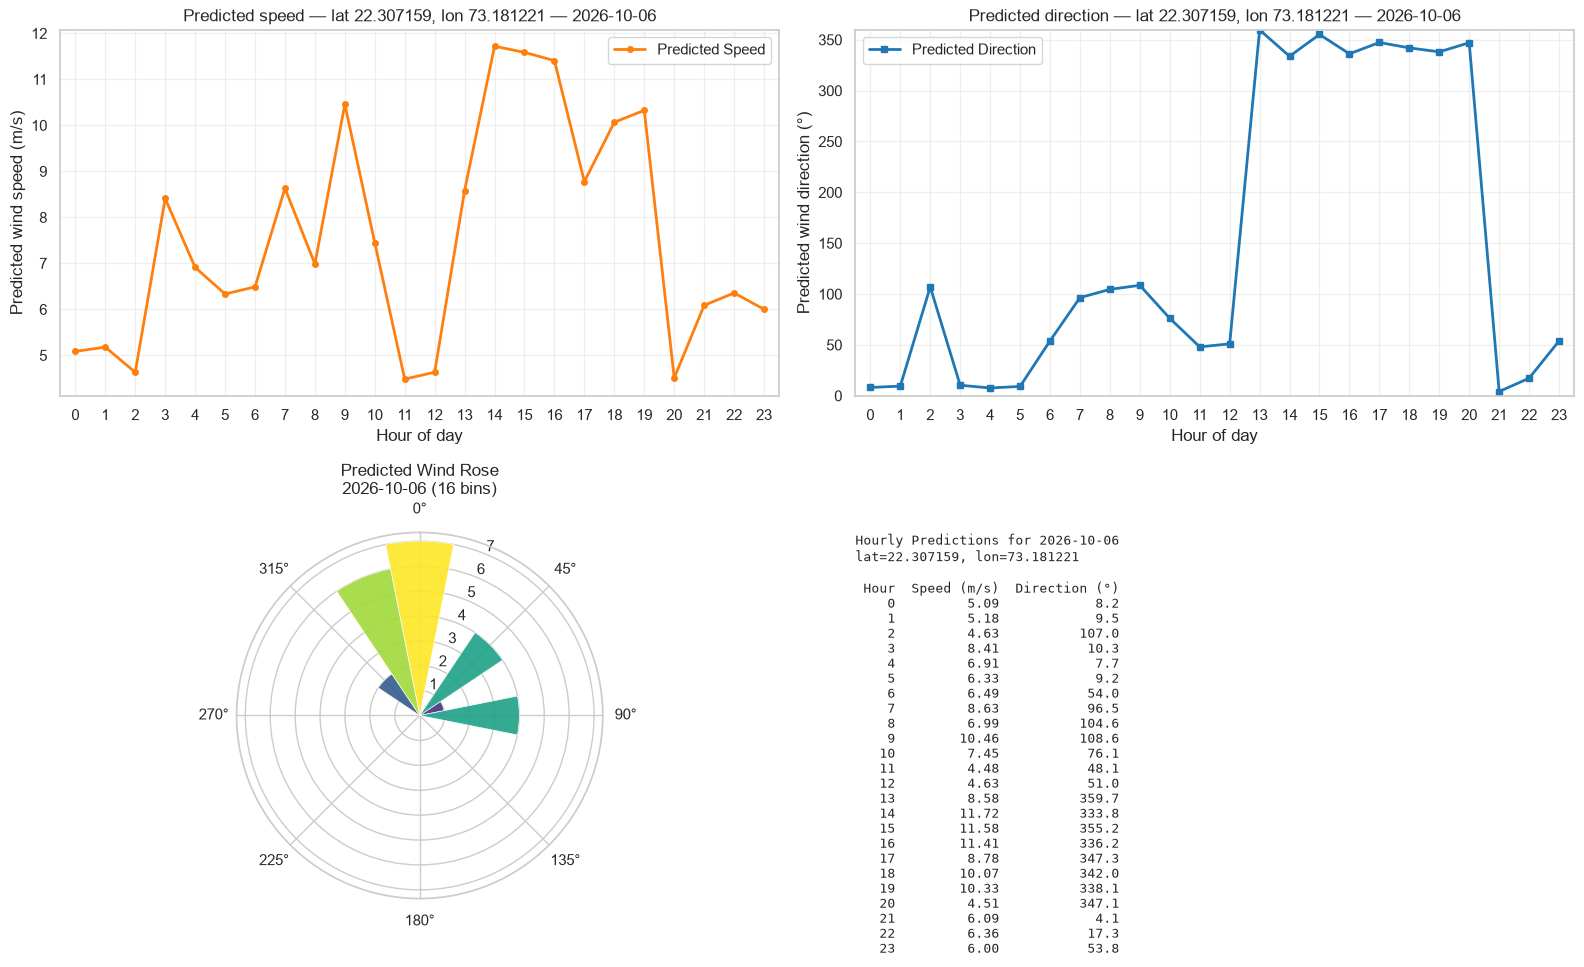


Hourly predictions table:
 Hour  Speed (m/s)  Direction (°)
    0         5.09            8.2
    1         5.18            9.5
    2         4.63          107.0
    3         8.41           10.3
    4         6.91            7.7
    5         6.33            9.2
    6         6.49           54.0
    7         8.63           96.5
    8         6.99          104.6
    9        10.46          108.6
   10         7.45           76.1
   11         4.48           48.1
   12         4.63           51.0
   13         8.58          359.7
   14        11.72          333.8
   15        11.58          355.2
   16        11.41          336.2
   17         8.78          347.3
   18        10.07          342.0
   19        10.33          338.1
   20         4.51          347.1
   21         6.09            4.1
   22         6.36           17.3
   23         6.00           53.8


In [9]:
# View Saved Predictions for a Specific Future Date - Hourly Intervals

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
from matplotlib.patches import Patch

print("📄 VIEW FUTURE PREDICTIONS FROM SAVED FILE")
print("="*50)

# Load predictions saved from the ML model output
pred_file = input("Enter predictions CSV filename (default hourly_predictions_Vadodara.csv): ").strip()
if not pred_file:
    pred_file = "hourly_predictions_Vadodara.csv"

try:
    pred_all = pd.read_csv(pred_file)
except Exception as e:
    print(f"❌ Could not read file '{pred_file}': {e}")
    raise

# Ensure date and hour columns from 'time'
if "date" not in pred_all.columns:
    dt = pd.to_datetime(pred_all.get("time", pd.Series([None]*len(pred_all))), errors="coerce")
    if dt.notna().any():
        pred_all["date"] = dt.dt.date.astype(str)
    else:
        tstr = pred_all["time"].astype(str)
        pred_all["date"] = tstr.str.split().str[0]

if "hour" not in pred_all.columns:
    dt2 = pd.to_datetime(pred_all.get("time", pd.Series([None]*len(pred_all))), errors="coerce")
    if dt2.notna().any():
        pred_all["hour"] = dt2.dt.hour
    else:
        pred_all["hour"] = pred_all["hour"].astype(int) if "hour" in pred_all.columns else 0

# Inputs: date and coordinate
default_tomorrow = (datetime.now() + timedelta(days=1)).strftime('%Y-%m-%d')
sel_date = input(f"Enter date to view (YYYY-MM-DD) [default {default_tomorrow}]: ").strip()
selected_date = sel_date if sel_date else default_tomorrow

try:
    lat_in = input("Enter latitude (blank = first available): ").strip()
    lon_in = input("Enter longitude (blank = first available): ").strip()
    if lat_in and lon_in:
        target_lat = float(lat_in)
        target_lon = float(lon_in)
    else:
        target_lat = float(pred_all.iloc[0]["lat"]) if "lat" in pred_all.columns else 22.3072
        target_lon = float(pred_all.iloc[0]["lon"]) if "lon" in pred_all.columns else 73.1812
except Exception:
    target_lat, target_lon = 22.3072, 73.1812

coord_tol = 1e-4
coord_mask = (
    pred_all["lat"].sub(target_lat).abs() <= coord_tol
) & (
    pred_all["lon"].sub(target_lon).abs() <= coord_tol
)

# Filter for selected date and coordinate
pt = pred_all[coord_mask].copy()
if pt.empty:
    print("❌ No rows found near the selected coordinates in the predictions file.")
else:
    pt_day = pt[pt["date"] == selected_date].copy()
    if pt_day.empty:
        print(f"⚠️  No predictions found for date {selected_date} at the selected coordinate.")
        print("Attempting to fetch hourly forecast for that date and generate predictions using the trained model...")
        try:
            import requests
            from datetime import datetime, date
            HOURLY_VARS = [
                "temperature_2m", "relative_humidity_2m", "dew_point_2m",
                "apparent_temperature", "precipitation", "rain", "snowfall",
                "snow_depth", "pressure_msl", "surface_pressure", "cloud_cover",
                "cloud_cover_low", "cloud_cover_mid", "cloud_cover_high",
                "wind_speed_10m", "wind_speed_100m",
                "wind_direction_10m", "wind_direction_100m",
                "wind_gusts_10m",
            ]
            sel_dt = datetime.strptime(selected_date, "%Y-%m-%d").date()
            today_dt = date.today()
            fc = None
            
            if sel_dt < today_dt:
                # Use archive API for past dates
                url = "https://archive-api.open-meteo.com/v1/archive"
                params = {
                    "latitude": target_lat,
                    "longitude": target_lon,
                    "hourly": HOURLY_VARS,
                    "timezone": "auto",
                    "start_date": selected_date,
                    "end_date": selected_date,
                }
                resp = requests.get(url, params=params, timeout=30)
                resp.raise_for_status()
                data = resp.json()
                if "hourly" not in data or not data["hourly"]:
                    raise ValueError("No hourly archive data returned.")
                fc = pd.DataFrame(data["hourly"]).copy()
            else:
                # Use forecast API for near future; fetch enough days to cover selected date
                max_horizon_days = 16
                delta_days = (sel_dt - today_dt).days + 1
                if delta_days < 1:
                    delta_days = 1
                if delta_days > max_horizon_days:
                    raise ValueError(f"Selected date {selected_date} beyond forecast horizon ({max_horizon_days} days).")
                url = "https://api.open-meteo.com/v1/forecast"
                params = {
                    "latitude": target_lat,
                    "longitude": target_lon,
                    "hourly": HOURLY_VARS,
                    "timezone": "auto",
                    "forecast_days": delta_days,
                }
                resp = requests.get(url, params=params, timeout=30)
                resp.raise_for_status()
                data = resp.json()
                if "hourly" not in data or not data["hourly"]:
                    raise ValueError("No hourly forecast returned.")
                fc = pd.DataFrame(data["hourly"]).copy()
            
            # Normalize time columns and filter to selected date
            fc["time"] = pd.to_datetime(fc["time"])
            fc["date"] = fc["time"].dt.date.astype(str)
            fc = fc[fc["date"] == selected_date].copy()
            if fc.empty:
                raise ValueError("Provider did not return data for the requested date after filtering.")
            fc["hour"] = fc["time"].dt.hour
            fc["lat"], fc["lon"] = target_lat, target_lon
            fc["direction"] = "Target"
            # Prepare features consistent with training
            feature_like = fc.copy()
            for col in ["time", "date"]:
                if col in feature_like.columns:
                    feature_like = feature_like.drop(columns=[col])
            # Drop target columns if present
            for col in ["wind_speed_100m", "wind_direction_100m", "temperature_2m", "wind_speed_10m", "wind_direction_10m"]:
                if col in feature_like.columns:
                    feature_like = feature_like.drop(columns=[col])
            # One-hot for objects if pipeline had any
            try:
                from pandas.api.types import is_object_dtype
                object_cols_pred = [c for c in feature_like.columns if is_object_dtype(feature_like[c])]
                if object_cols_pred:
                    feature_like = pd.get_dummies(feature_like, columns=object_cols_pred, dtype=float)
            except Exception:
                pass
            # Ensure feature columns align (load from disk if not in memory)
            if 'FEATURE_COLUMNS' not in globals() and 'FEATURE_COLUMNS' not in locals():
                try:
                    import json
                    with open("feature_columns.json", "r", encoding="utf-8") as f:
                        FEATURE_COLUMNS = json.load(f)
                except Exception as e:
                    raise RuntimeError(f"Model feature list not found. Please run training once to persist artifacts. ({e})")
            for feat in FEATURE_COLUMNS:
                if feat not in feature_like.columns:
                    feature_like[feat] = 0.0
            feature_like = feature_like[FEATURE_COLUMNS]
            # Predict using models (load from disk if not in memory)
            if 'speed_model_' not in globals() and 'speed_model_' not in locals():
                try:
                    import joblib
                    speed_model_ = joblib.load("speed_model.pkl")
                except Exception as e:
                    raise RuntimeError(f"Speed model not available. Run training to persist artifacts. ({e})")
            if 'dir_model_' not in globals() and 'dir_model_' not in locals():
                try:
                    import joblib
                    dir_model_ = joblib.load("dir_model.pkl")
                except Exception as e:
                    raise RuntimeError(f"Direction model not available. Run training to persist artifacts. ({e})")
            pred_speed = speed_model_.predict(feature_like)
            pred_dir_vec = dir_model_.predict(feature_like)
            pred_cos, pred_sin = pred_dir_vec[:, 0], pred_dir_vec[:, 1]
            norm = np.hypot(pred_cos, pred_sin)
            norm[norm == 0] = 1.0
            pred_cos /= norm
            pred_sin /= norm
            pred_dir_deg = (np.rad2deg(np.arctan2(pred_sin, pred_cos)) + 360) % 360
            fc["pred_wind_speed_100m"], fc["pred_wind_direction_100m_deg"] = pred_speed, pred_dir_deg
            pt_day = fc.copy()
            print("✅ Forecast fetched and predictions generated.")
        except Exception as e:
            print(f"❌ Could not fetch forecast/generate predictions: {e}")
            pt_day = pd.DataFrame()

    # Plot if we now have data
    if not pt_day.empty:
        pt_day["hour_int"] = pd.to_numeric(pt_day["hour"], errors="coerce").astype("Int64")
        pt_day = pt_day.dropna(subset=["hour_int"]).copy()
        pt_day["hour_int"] = pt_day["hour_int"].astype(int)

        speed_col = "pred_wind_speed_100m"
        dir_col = "pred_wind_direction_100m_deg"
        if speed_col not in pt_day.columns or dir_col not in pt_day.columns:
            print(f"❌ Missing required prediction columns in file: {speed_col}, {dir_col}")
        else:
            sns.set(style="whitegrid")
            fig = plt.figure(figsize=(16, 10))

            # Top Left: Predicted wind speed per hour
            ax1 = fig.add_subplot(2, 2, 1)
            pt_day_sorted = pt_day.sort_values(["hour_int"]).copy()
            ax1.plot(pt_day_sorted["hour_int"], pt_day_sorted[speed_col], color="tab:orange", linewidth=2,
                     label="Predicted Speed", marker='o', markersize=4)
            ax1.set_xlim(-0.5, 23.5)
            ax1.set_xticks(list(range(0, 24)))
            ax1.set_xlabel("Hour of day")
            ax1.set_ylabel("Predicted wind speed (m/s)")
            ax1.set_title(f"Predicted speed — lat {target_lat:.6f}, lon {target_lon:.6f} — {selected_date}")
            ax1.legend()
            ax1.grid(True, alpha=0.3)

            # Top Right: Predicted wind direction per hour
            ax2 = fig.add_subplot(2, 2, 2)
            ax2.plot(pt_day_sorted["hour_int"], pt_day_sorted[dir_col], color="tab:blue", linewidth=2,
                     label="Predicted Direction", marker='s', markersize=4)
            ax2.set_xlim(-0.5, 23.5)
            ax2.set_xticks(list(range(0, 24)))
            ax2.set_xlabel("Hour of day")
            ax2.set_ylabel("Predicted wind direction (°)")
            ax2.set_ylim(0, 360)
            ax2.set_title(f"Predicted direction — lat {target_lat:.6f}, lon {target_lon:.6f} — {selected_date}")
            ax2.legend()
            ax2.grid(True, alpha=0.3)

            # Bottom Left: Wind rose of predicted directions
            ax3 = fig.add_subplot(2, 2, 3, projection="polar")
            directions_deg = pt_day_sorted[dir_col].dropna().values
            directions_rad = np.deg2rad(directions_deg % 360)
            nbins = 16
            bins = np.linspace(0, 2*np.pi, nbins + 1)
            counts, _ = np.histogram(directions_rad, bins=bins)
            widths = np.diff(bins)
            bars = ax3.bar(bins[:-1], counts, width=widths, bottom=0.0,
                           color=plt.cm.viridis(counts / counts.max() if counts.max() > 0 else counts),
                           edgecolor="white", linewidth=0.5, alpha=0.9)
            ax3.set_theta_zero_location("N")
            ax3.set_theta_direction(-1)
            ax3.set_title(f"Predicted Wind Rose\n{selected_date} (16 bins)")

            # Bottom Right: Table summary inline
            ax4 = fig.add_subplot(2, 2, 4)
            ax4.axis('off')
            tbl = pt_day_sorted[["hour_int", speed_col, dir_col]].copy()
            tbl.columns = ["Hour", "Speed (m/s)", "Direction (°)"]
            tbl["Speed (m/s)"] = tbl["Speed (m/s)"].round(2)
            tbl["Direction (°)"] = tbl["Direction (°)"].round(1)
            table_text = tbl.to_string(index=False)
            ax4.text(0.0, 1.0, f"Hourly Predictions for {selected_date}\nlat={target_lat:.6f}, lon={target_lon:.6f}\n\n" + table_text,
                     va='top', ha='left', family='monospace', fontsize=9)

            plt.tight_layout()
            plt.show()

            # Also print to console for copy/paste
            print("\nHourly predictions table:")
            print(table_text)
        
    else:
        print("❌ No data available to plot after forecast/archive fetch.")

